# Credit Risk Prediction & Default Analysis
**Role:** Machine Learning Analyst  |  **Data:** `credit.csv` (1,000 loan applicants)  |  **Target:** `default` (0 = Good loan, 1 = Defaulting loan)

**Business goal.** Reduce the bank's *bad-debt ratio* by flagging high-risk applicants **before** a loan is approved, while not unfairly rejecting good customers.

**Workflow**
1. Exploratory Data Analysis (EDA)
2. Data Preprocessing
3. Model Training (Logistic Regression, Decision Tree, Random Forest, SVM)
4. Evaluation with **Recall, F1-score, AUC-ROC** (accuracy is reported but is *not* the primary metric)
5. Threshold tuning, explainability and fairness check
6. Business impact & recommendations

In [1]:
import warnings, json, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report, precision_recall_curve)

RANDOM_STATE = 42
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)

# One consistent colour language: blue = Good (non-default), red = Default
C_GOOD, C_BAD, C_NEUTRAL = "#2E6F9E", "#D1495B", "#8A94A0"
sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

def save(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=160, bbox_inches="tight")

## 1. Load the data

In [2]:
df = pd.read_csv("credit.csv")
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (1000, 23)


,observation_id,checking_balance,months_loan_duration,credit_history,purpose,amount,savings_balance,employment_length,installment_rate,personal_status,...,age,installment_plan,housing,existing_credits,default,dependents,telephone,foreign_worker,job,gender
0,0,-43.0,6,critical,radio/tv,1169,NaN,13 years,4,single,...,67,none,own,2,0,1,2.349340e+09,yes,skilled employee,male
1,1,75.0,48,repaid,radio/tv,5951,89.0,2 years,2,NaN,...,22,none,own,1,1,1,NaN,yes,skilled employee,female
2,2,NaN,12,critical,education,2096,24.0,5 years,2,single,...,49,none,own,1,0,2,NaN,yes,unskilled resident,male
3,3,-32.0,42,repaid,furniture,7882,9.0,5 years,2,single,...,45,none,for free,1,0,2,NaN,yes,skilled employee,male
4,4,-23.0,24,delayed,car (new),4870,43.0,3 years,3,single,...,53,none,for free,2,1,2,NaN,yes,skilled employee,male


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   observation_id        1000 non-null   int64  
 1   checking_balance      606 non-null    float64
 2   months_loan_duration  1000 non-null   int64  
 3   credit_history        1000 non-null   str    
 4   purpose               1000 non-null   str    
 5   amount                1000 non-null   int64  
 6   savings_balance       817 non-null    float64
 7   employment_length     938 non-null    str    
 8   installment_rate      1000 non-null   int64  
 9   personal_status       690 non-null    str    
 10  other_debtors         1000 non-null   str    
 11  residence_history     870 non-null    str    
 12  property              1000 non-null   str    
 13  age                   1000 non-null   int64  
 14  installment_plan      1000 non-null   str    
 15  housing               1000 non-nu

## 2. Exploratory Data Analysis (EDA)
### 2.1 Data quality: missing values and column quirks

In [3]:
missing = (df.isna().sum().to_frame("missing_count")
             .assign(missing_pct=lambda d: (d.missing_count / len(df) * 100).round(1))
             .query("missing_count > 0").sort_values("missing_count", ascending=False))
display(missing)

print("Duplicate rows (excluding observation_id):", df.drop(columns="observation_id").duplicated().sum())
print("Unique values -> telephone:", df.telephone.nunique(), "| employment_length:", df.employment_length.nunique(),
      "| residence_history:", df.residence_history.nunique())
print("\nCross-check personal_status vs gender (NaN personal_status rows):")
print(pd.crosstab(df.personal_status.fillna("<missing>"), df.gender))

,missing_count,missing_pct
telephone,596,59.6
checking_balance,394,39.4
personal_status,310,31.0
savings_balance,183,18.3
residence_history,130,13.0
employment_length,62,6.2


Duplicate rows (excluding observation_id): 0
Unique values -> telephone: 404 | employment_length: 31 | residence_history: 36

Cross-check personal_status vs gender (NaN personal_status rows):
gender           female  male
personal_status              
<missing>           310     0
divorced              0    50
married               0    92
single                0   548


**What the missing values actually mean** (important: they are *not* random):

| Column | Observation | Treatment |
|---|---|---|
| `checking_balance` (39% missing), `savings_balance` (18%) | Missing most likely means *no such account*; we test this below | Keep a **"has account" flag** instead of blindly imputing |
| `telephone` (60% missing) | Contains a phone number (identifier) when present | Convert to a **`has_telephone`** flag; never use the number itself |
| `personal_status` (31% missing) | Missing for **every** female applicant (status not recorded for women) | Label as `female (status not recorded)` |
| `employment_length`, `residence_history` | Text such as "13 years" / "5 months" | Parse to **months** (numeric); impute the few missing with the median |

### 2.2 Target distribution

default
0    700
1    300
Name: count, dtype: int64 
Default rate: 30.0%


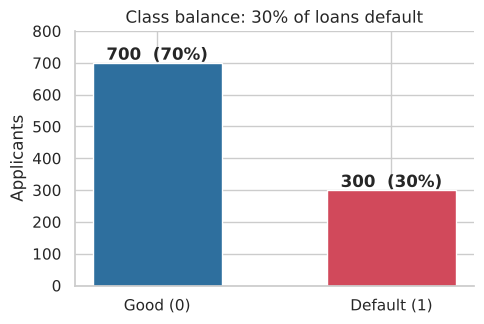

In [4]:
counts = df.default.value_counts().sort_index()
print(counts, "\nDefault rate: %.1f%%" % (df.default.mean() * 100))

fig, ax = plt.subplots(figsize=(5, 3.4))
bars = ax.bar(["Good (0)", "Default (1)"], counts.values, color=[C_GOOD, C_BAD], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 10, f"{v}  ({v / len(df):.0%})", ha="center", fontweight="bold")
ax.set_ylabel("Applicants"); ax.set_title("Class balance: 30% of loans default"); ax.set_ylim(0, 800)
plt.tight_layout(); save("01_target_distribution"); plt.show()

The classes are **imbalanced (70 / 30)**. A model that approves everybody would be 70% accurate but would miss every default, which is why accuracy is not the metric we optimise. We use `class_weight='balanced'` and stratified splits.

### 2.3 Numeric features: distributions and outliers

In [5]:
num_cols = ["months_loan_duration", "amount", "age", "checking_balance", "savings_balance",
            "installment_rate", "existing_credits", "dependents"]
display(df[num_cols].describe().T.round(1))

def iqr_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

out_tbl = pd.DataFrame({"IQR outliers": {c: iqr_outliers(df[c]) for c in num_cols},
                        "max": df[num_cols].max()})
display(out_tbl)

,count,mean,std,min,25%,50%,75%,max
months_loan_duration,1000.0,20.9,12.1,4.0,12.0,18.0,24.0,72.0
amount,1000.0,3271.3,2822.7,250.0,1365.5,2319.5,3972.2,18424.0
age,1000.0,35.5,11.4,19.0,27.0,33.0,42.0,75.0
checking_balance,606.0,97.2,206.9,-50.0,-23.0,24.0,131.8,999.0
savings_balance,817.0,781.6,3017.0,0.0,31.0,64.0,128.0,19972.0
installment_rate,1000.0,3.0,1.1,1.0,2.0,3.0,4.0,4.0
existing_credits,1000.0,1.4,0.6,1.0,1.0,1.0,2.0,4.0
dependents,1000.0,1.2,0.4,1.0,1.0,1.0,1.0,2.0


,IQR outliers,max
months_loan_duration,70,72.0
amount,72,18424.0
age,23,75.0
checking_balance,55,999.0
savings_balance,173,19972.0
installment_rate,0,4.0
existing_credits,6,4.0
dependents,155,2.0


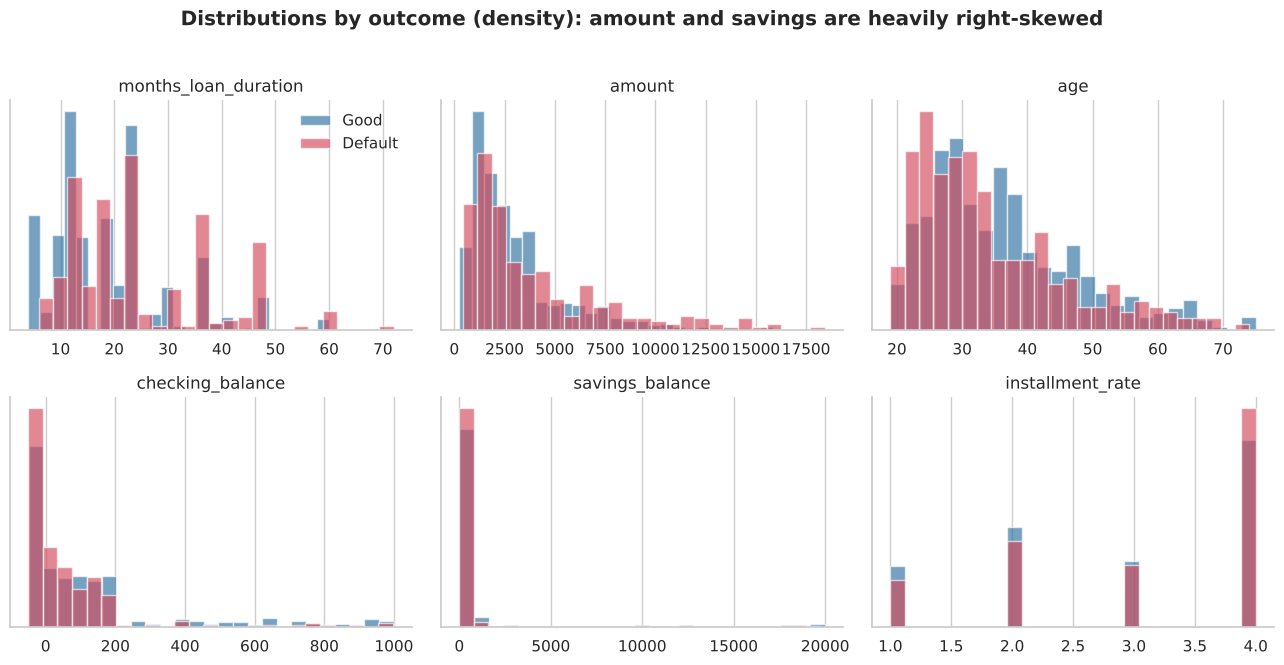

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axes.ravel(), ["months_loan_duration", "amount", "age", "checking_balance", "savings_balance", "installment_rate"]):
    for lab, col, name in [(0, C_GOOD, "Good"), (1, C_BAD, "Default")]:
        ax.hist(df.loc[df.default == lab, c].dropna(), bins=25, alpha=.65, color=col, label=name, density=True)
    ax.set_title(c); ax.set_yticks([])
axes[0, 0].legend(frameon=False)
fig.suptitle("Distributions by outcome (density): amount and savings are heavily right-skewed", y=1.02, fontweight="bold")
plt.tight_layout(); save("02_numeric_distributions"); plt.show()

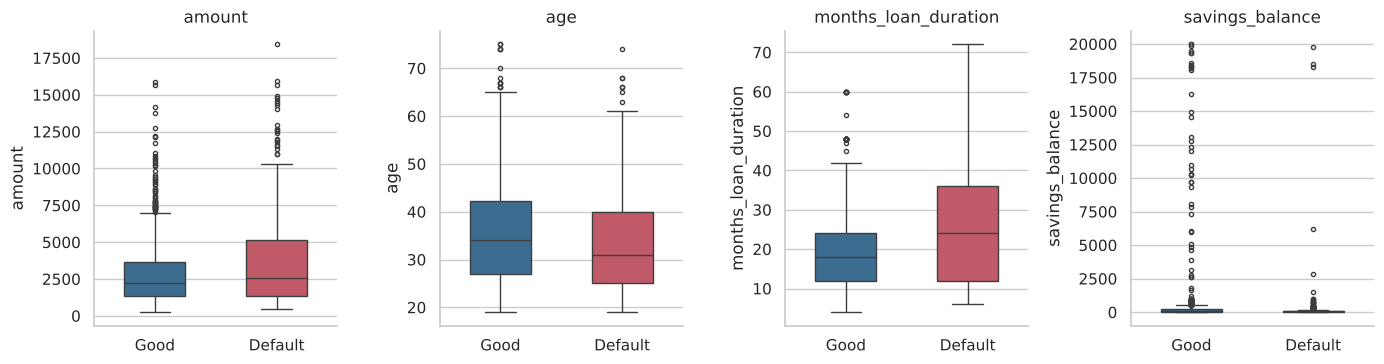

checking_balance == 999 rows: 1 (a sentinel-like extreme value; the next-largest is 997.0 )
savings_balance max: 19972.0 | 99th pct: 18475.0


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, c in zip(axes, ["amount", "age", "months_loan_duration", "savings_balance"]):
    sns.boxplot(data=df, x="default", y=c, hue="default", palette=[C_GOOD, C_BAD], ax=ax, legend=False, width=.5, fliersize=3)
    ax.set_xticks([0, 1], ["Good", "Default"]); ax.set_xlabel(""); ax.set_title(c)
plt.tight_layout(); save("03_boxplots_outliers"); plt.show()

print("checking_balance == 999 rows:", (df.checking_balance == 999).sum(), "(a sentinel-like extreme value; the next-largest is",
      df.checking_balance[df.checking_balance < 999].max(), ")")
print("savings_balance max:", df.savings_balance.max(), "| 99th pct:", df.savings_balance.quantile(.99).round(0))

**Outlier handling decision.** Loan `amount` and `savings_balance` are heavy-tailed, and `checking_balance` has one extreme value (999). These are real customers, not errors, so we **keep them** but tame their influence: `log1p` transform for amount and savings, and cap `checking_balance` at its 99th percentile. Tree models are unaffected by this; Logistic Regression and SVM benefit.

### 2.4 Which categories carry more default risk?

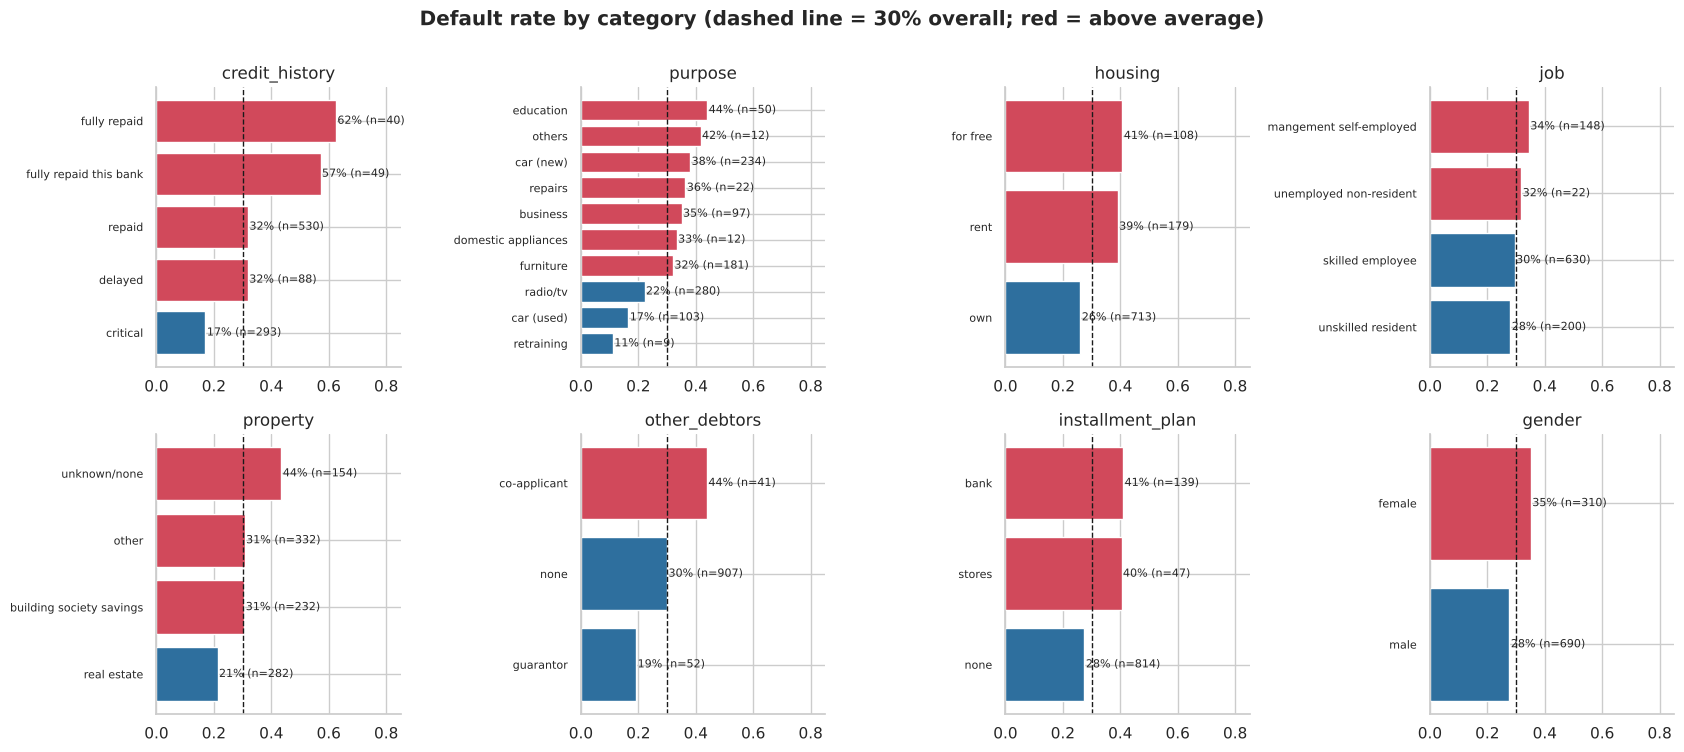

In [8]:
cat_cols = ["credit_history", "purpose", "housing", "job", "property", "other_debtors", "installment_plan", "gender"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
base = df.default.mean()
for ax, c in zip(axes.ravel(), cat_cols):
    r = df.groupby(c).default.agg(["mean", "size"]).sort_values("mean")
    ax.barh(r.index, r["mean"], color=[C_BAD if v > base else C_GOOD for v in r["mean"]])
    ax.axvline(base, color="k", ls="--", lw=1)
    for i, (m, n) in enumerate(zip(r["mean"], r["size"])):
        ax.text(m + .005, i, f"{m:.0%} (n={n})", va="center", fontsize=8)
    ax.set_title(c); ax.set_xlim(0, .85); ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Default rate by category (dashed line = 30% overall; red = above average)", y=1.0, fontweight="bold")
plt.tight_layout(); save("04_default_rate_by_category"); plt.show()

### 2.5 Are missing balances informative?

,feature,status,default_rate,n
0,Checking account,Missing / none,11.7,394
1,Checking account,Recorded,41.9,606
2,Savings account,Missing / none,17.5,183
3,Savings account,Recorded,32.8,817
4,Telephone,Missing / none,31.4,596
5,Telephone,Recorded,28.0,404


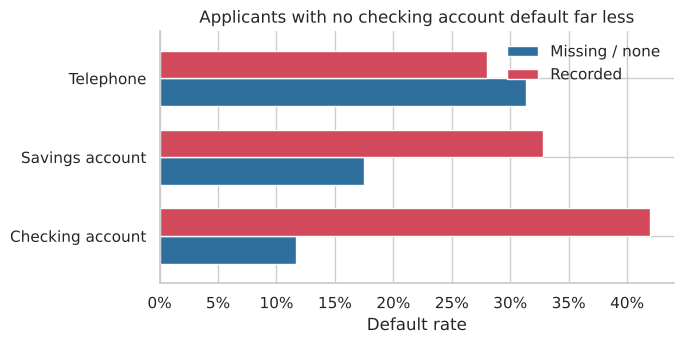

In [9]:
miss_rows = []
for col, label in [("checking_balance", "Checking account"), ("savings_balance", "Savings account"), ("telephone", "Telephone")]:
    g = df.groupby(df[col].isna()).default.agg(["mean", "size"])
    miss_rows += [(label, "Missing / none", g.loc[True, "mean"], g.loc[True, "size"]),
                  (label, "Recorded", g.loc[False, "mean"], g.loc[False, "size"])]
miss_df = pd.DataFrame(miss_rows, columns=["feature", "status", "default_rate", "n"])
display(miss_df.assign(default_rate=lambda d: (d.default_rate * 100).round(1)))

fig, ax = plt.subplots(figsize=(7, 3.6))
piv = miss_df.pivot(index="feature", columns="status", values="default_rate")[["Missing / none", "Recorded"]]
piv.plot.barh(ax=ax, color=[C_GOOD, C_BAD], width=.7)
ax.set_xlabel("Default rate"); ax.set_ylabel(""); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Applicants with no checking account default far less"); ax.legend(frameon=False, title="")
plt.tight_layout(); save("05_missingness_vs_default"); plt.show()

Missingness is **highly informative**: applicants with no recorded checking balance default at less than a third of the rate of those with one. Imputing these with a mean would destroy that signal, so we add explicit flags.

### 2.6 Numeric relationships

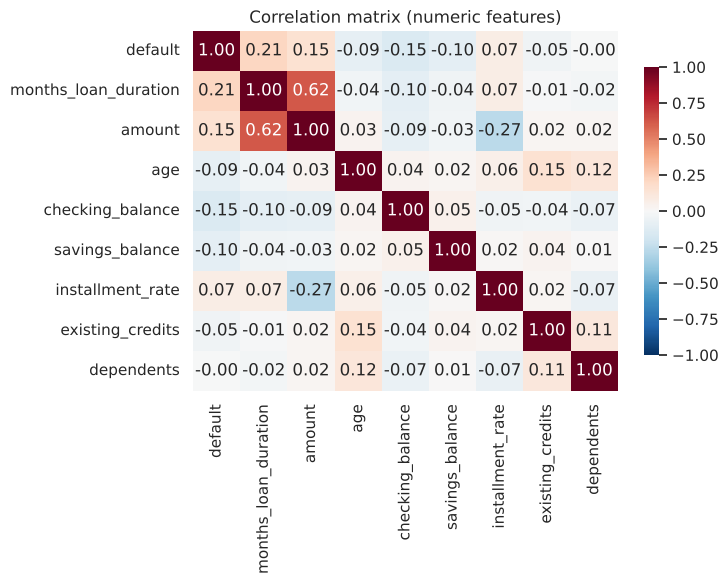

,corr with default
months_loan_duration,0.215
amount,0.155
checking_balance,-0.148
savings_balance,-0.097
age,-0.091
installment_rate,0.072
existing_credits,-0.046
dependents,-0.003


In [10]:
corr = df[["default", "months_loan_duration", "amount", "age", "checking_balance", "savings_balance",
           "installment_rate", "existing_credits", "dependents"]].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlation matrix (numeric features)")
plt.tight_layout(); save("06_correlation"); plt.show()
display(corr["default"].drop("default").sort_values(key=abs, ascending=False).round(3).to_frame("corr with default"))

### 2.7 EDA takeaways
* **Loan size and duration matter:** longer, larger loans default more often.
* **Credit history, account status and loan purpose** show large differences in default rate between categories.
* **Missing account data is a signal**, not noise.
* No single numeric feature is strongly correlated with default (all |r| < 0.25), so we need a **multivariate model** rather than one rule of thumb.

## 3. Data Preprocessing
Steps (all fitted on the **training set only**, inside a pipeline, to prevent data leakage):
1. Parse text durations to numeric months; build missing-value flags; drop identifiers (`observation_id`, raw `telephone` number).
2. Handle outliers (log transform / capping).
3. Impute remaining numeric gaps (median).
4. One-hot encode categorical text; standard-scale numeric features.
5. **Responsible-lending choice:** drop `gender` and `personal_status` from the model inputs (see the sensitivity test in section 7.2: no loss of predictive power).

In [11]:
data = df.copy()

def to_months(s):
    """'13 years' -> 156, '5 months' -> 5, NaN -> NaN"""
    if pd.isna(s): return np.nan
    n, unit = s.split()
    return float(n) * 12 if unit.startswith("year") else float(n)

data["employment_months"] = data.employment_length.map(to_months)
data["residence_months"]  = data.residence_history.map(to_months)

# Missing = "no such account / no phone": keep that information as flags
data["has_checking"]  = data.checking_balance.notna().astype(int)
data["has_savings"]   = data.savings_balance.notna().astype(int)
data["has_telephone"] = data.telephone.notna().astype(int)

# Outliers: cap the extreme checking balance at the 99th percentile, log-transform skewed money columns
data["checking_balance"] = data.checking_balance.clip(upper=data.checking_balance.quantile(.99))
data["log_amount"]  = np.log1p(data.amount)
data["log_savings"] = np.log1p(data.savings_balance)

# Sensitive attributes kept aside for the fairness audit only
data["personal_status"] = data.personal_status.fillna("female (status not recorded)")

NUM = ["checking_balance", "months_loan_duration", "log_amount", "log_savings", "installment_rate", "age",
       "existing_credits", "dependents", "employment_months", "residence_months",
       "has_checking", "has_savings", "has_telephone"]
CAT = ["credit_history", "purpose", "other_debtors", "property", "installment_plan", "housing", "foreign_worker", "job"]

X, y = data[NUM + CAT], data["default"]
print("Model features:", X.shape[1], "| remaining missing values handled by the imputer:",
      int(X.isna().sum().sum()))

Model features: 21 | remaining missing values handled by the imputer: 769


In [12]:
# Stratified 80/20 split keeps the 30% default rate in both sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows ({y_train.mean():.1%} default) | Test: {X_test.shape[0]} rows ({y_test.mean():.1%} default)")

def make_preprocessor(num, cat):
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])

preprocessor = make_preprocessor(NUM, CAT)
preprocessor.fit(X_train)
print("Feature matrix after encoding + scaling:", preprocessor.transform(X_train).shape)

Train: 800 rows (30.0% default) | Test: 200 rows (30.0% default)
Feature matrix after encoding + scaling: (800, 47)


## 4. Model Training
Four classifiers are tuned with **5-fold stratified cross-validation** on the training set. Because missing a default is the costly mistake, every model uses `class_weight='balanced'` and hyper-parameters are chosen to maximise **F1 of the Default class** (balances catching defaults against rejecting good customers).

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_space = {
    "Logistic Regression": (LogisticRegression(class_weight="balanced", max_iter=2000),
                            {"model__C": [0.01, 0.1, 1, 10]}),
    "Decision Tree":       (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                            {"model__max_depth": [3, 4, 5, 7], "model__min_samples_leaf": [5, 10, 20]}),
    "Random Forest":       (RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
                            {"model__n_estimators": [300], "model__max_depth": [5, 8, None], "model__min_samples_leaf": [2, 5]}),
    "SVM (RBF)":           (SVC(class_weight="balanced", probability=True, random_state=RANDOM_STATE),
                            {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01]}),
}

tuned, best_params = {}, {}
for name, (estimator, grid) in search_space.items():
    gs = GridSearchCV(Pipeline([("prep", make_preprocessor(NUM, CAT)), ("model", estimator)]),
                      grid, scoring="f1", cv=cv, n_jobs=-1).fit(X_train, y_train)
    tuned[name], best_params[name] = gs.best_estimator_, gs.best_params_
    print(f"{name:20s} best CV F1 = {gs.best_score_:.3f}  {gs.best_params_}")

Logistic Regression  best CV F1 = 0.579  {'model__C': 0.01}


Decision Tree        best CV F1 = 0.550  {'model__max_depth': 3, 'model__min_samples_leaf': 20}


Random Forest        best CV F1 = 0.602  {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 300}


SVM (RBF)            best CV F1 = 0.601  {'model__C': 10, 'model__gamma': 0.01}


## 5. Model Evaluation
### 5.1 Model comparison
*Model selection uses cross-validated predictions on the training data only* (so the test set is not used to pick the winner), then the untouched **test set** gives the final honest numbers.

In [14]:
def metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred), "AUC-ROC": roc_auc_score(y_true, proba)}

# (a) Cross-validated out-of-fold predictions on TRAIN -> used for model selection
oof = {n: cross_val_predict(clone(m), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1] for n, m in tuned.items()}
cv_tbl = pd.DataFrame({n: metrics(y_train, p) for n, p in oof.items()}).T
cv_tbl["Selection score"] = cv_tbl[["Recall", "F1", "AUC-ROC"]].mean(axis=1)   # equal weight on the three business metrics
display(Markdown("**Cross-validated (training data)**")); display(cv_tbl.round(3))

# (b) Held-out TEST performance
test_proba = {n: m.predict_proba(X_test)[:, 1] for n, m in tuned.items()}
test_tbl = pd.DataFrame({n: metrics(y_test, p) for n, p in test_proba.items()}).T
display(Markdown("**Held-out test set (200 applicants, threshold 0.5)**")); display(test_tbl.round(3))

best_name = cv_tbl["Selection score"].idxmax()
display(Markdown(f"### Selected model: **{best_name}** (highest mean of Recall, F1 and AUC in cross-validation)"))

**Cross-validated (training data)**

,Accuracy,Precision,Recall,F1,AUC-ROC,Selection score
Logistic Regression,0.684,0.482,0.729,0.580,0.768,0.693
Decision Tree,0.611,0.421,0.792,0.550,0.702,0.681
Random Forest,0.746,0.568,0.642,0.603,0.795,0.680
SVM (RBF),0.746,0.623,0.392,0.481,0.777,0.550


**Held-out test set (200 applicants, threshold 0.5)**

,Accuracy,Precision,Recall,F1,AUC-ROC
Logistic Regression,0.725,0.527,0.800,0.636,0.803
Decision Tree,0.605,0.423,0.867,0.568,0.697
Random Forest,0.770,0.597,0.717,0.652,0.805
SVM (RBF),0.800,0.727,0.533,0.615,0.829


### Selected model: **Logistic Regression** (highest mean of Recall, F1 and AUC in cross-validation)

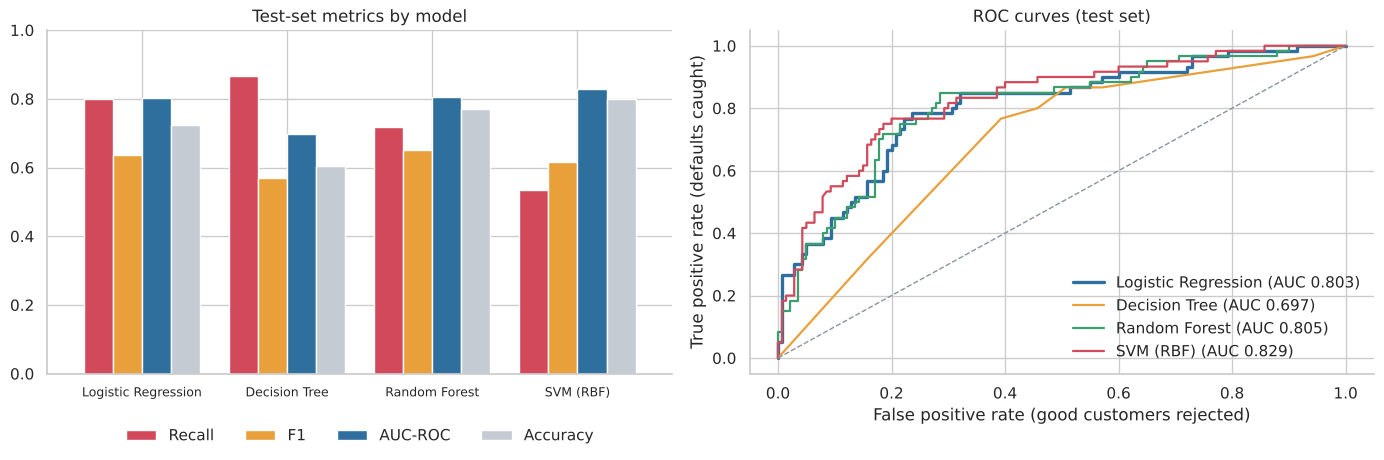

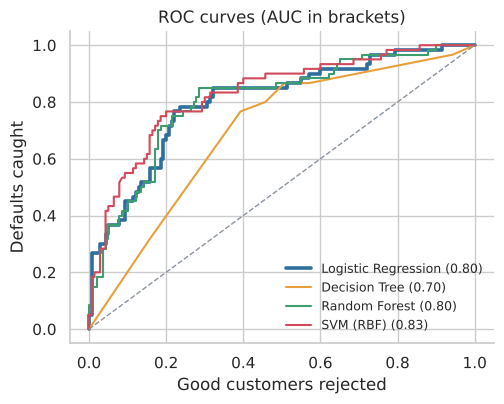

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Metric comparison
plot_df = test_tbl[["Recall", "F1", "AUC-ROC", "Accuracy"]]
plot_df.plot.bar(ax=axes[0], color=[C_BAD, "#E9A03B", C_GOOD, "#C5CBD3"], width=.8, rot=0)
axes[0].set_ylim(0, 1); axes[0].set_title("Test-set metrics by model"); axes[0].legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.12))
axes[0].tick_params(axis="x", labelsize=9)

# ROC curves
palette = {"Logistic Regression": C_GOOD, "Decision Tree": "#E9A03B", "Random Forest": "#3C9D6E", "SVM (RBF)": C_BAD}
for n, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, lw=2.4 if n == best_name else 1.6, color=palette[n], label=f"{n} (AUC {roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color=C_NEUTRAL, lw=1)
axes[1].set_xlabel("False positive rate (good customers rejected)"); axes[1].set_ylabel("True positive rate (defaults caught)")
axes[1].set_title("ROC curves (test set)"); axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); save("07_model_comparison_roc"); plt.show()

# Stand-alone ROC chart (reused in the business deck)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for n, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=2.6 if n == best_name else 1.5, color=palette[n], label=f"{n} ({roc_auc_score(y_test, p):.2f})")
ax.plot([0, 1], [0, 1], "--", color=C_NEUTRAL, lw=1)
ax.set_xlabel("Good customers rejected"); ax.set_ylabel("Defaults caught"); ax.set_title("ROC curves (AUC in brackets)")
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.tight_layout(); save("07b_roc_curves"); plt.show()

### 5.2 Confusion matrices (threshold 0.5)

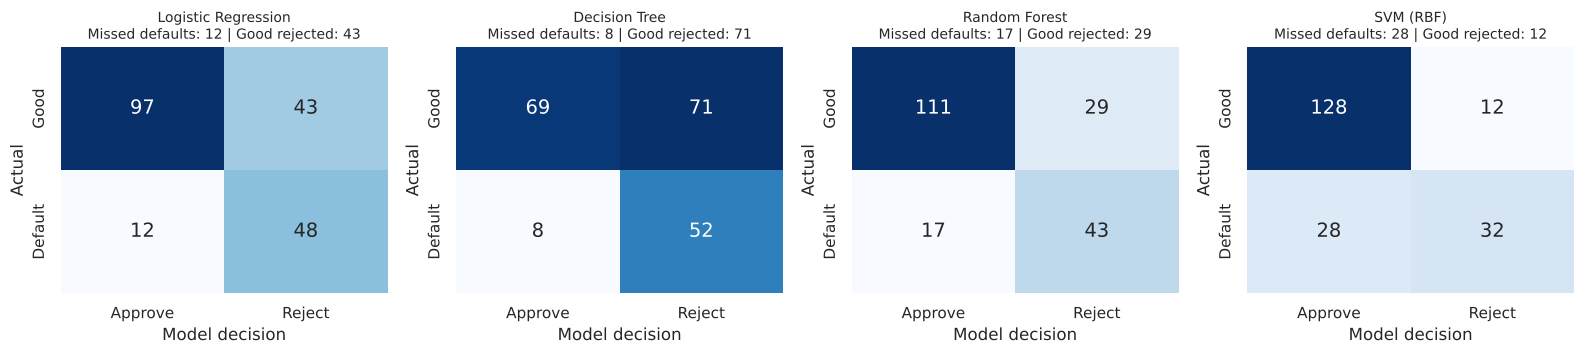

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.7))
for ax, (n, p) in zip(axes, test_proba.items()):
    cm = confusion_matrix(y_test, (p >= .5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["Approve", "Reject"], yticklabels=["Good", "Default"])
    ax.set_title(f"{n}\nMissed defaults: {cm[1, 0]} | Good rejected: {cm[0, 1]}", fontsize=10)
    ax.set_xlabel("Model decision"); ax.set_ylabel("Actual")
plt.tight_layout(); save("08_confusion_matrices"); plt.show()

## 6. Threshold Tuning: turning scores into lending decisions
A default probability must be converted into *approve / reject*, and the threshold is a **business policy dial**: lowering it catches more defaults but also rejects more good customers. We compare two policies, both set using the training out-of-fold predictions only (never the test set):

* **Balanced (recommended):** the threshold that maximises **F1** subject to **Recall >= 80%**. The brief says high recall is vital, and F1 keeps the rejection of good customers in check.
* **Strict (cost-optimal):** the threshold that minimises the money lost on wrong decisions. Approving a loan that defaults loses `amount x LGD` (the brief: the "entire principal", so LGD = 100%); rejecting a good customer loses `amount x margin`. The margin is **not in the data**, so we **assume 10%**.

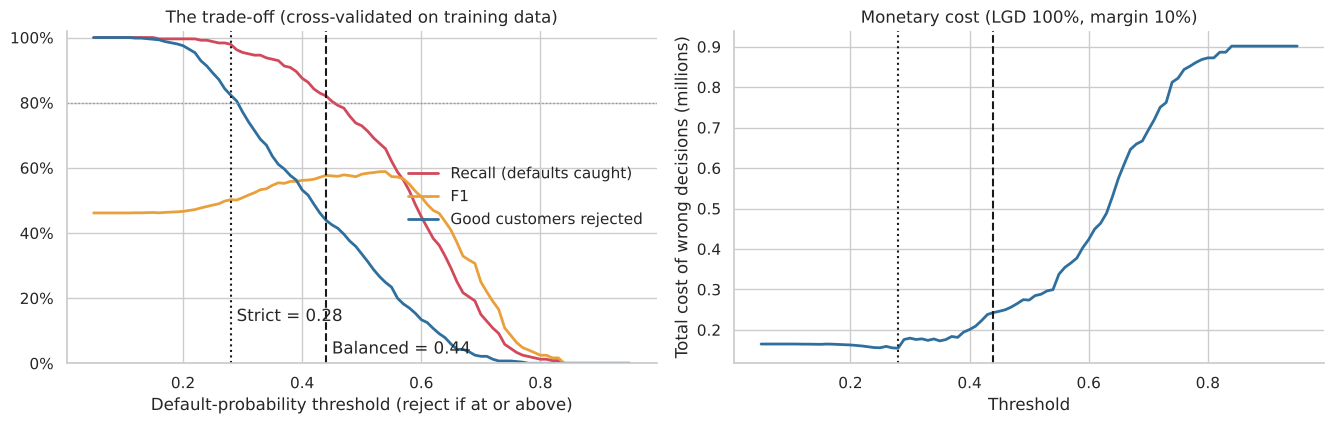

Balanced threshold (max F1 with recall >= 80%): 0.44
Strict, cost-minimising threshold: 0.28


In [17]:
LGD, MARGIN, RECALL_TARGET = 1.00, 0.10, 0.80     # business assumptions / policy targets (editable)

amount_train = data.loc[X_train.index, "amount"].values
amount_test  = data.loc[X_test.index,  "amount"].values
oof_best     = oof[best_name]
thresholds   = np.round(np.arange(0.05, 0.96, 0.01), 2)

def total_cost(y_true, proba, amount, thr, lgd=LGD, margin=MARGIN):
    pred = proba >= thr
    missed_default_loss = (amount * lgd)[(~pred) & (y_true == 1)].sum()     # approved a defaulter
    lost_margin         = (amount * margin)[pred & (y_true == 0)].sum()      # rejected a good customer
    return missed_default_loss + lost_margin

rec_curve  = np.array([recall_score(y_train, oof_best >= t) for t in thresholds])
f1_curve   = np.array([f1_score(y_train, oof_best >= t) for t in thresholds])
rej_good   = np.array([(oof_best[y_train.values == 0] >= t).mean() for t in thresholds])
cost_curve = np.array([total_cost(y_train.values, oof_best, amount_train, t) for t in thresholds])

# Policy 1: best F1 among thresholds that still reach the recall target
ok = rec_curve >= RECALL_TARGET
THR = float(thresholds[ok][f1_curve[ok].argmax()])
# Policy 2: minimum monetary cost
STRICT_THR = float(thresholds[cost_curve.argmin()])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
axes[0].plot(thresholds, rec_curve, color=C_BAD, lw=2, label="Recall (defaults caught)")
axes[0].plot(thresholds, f1_curve, color="#E9A03B", lw=2, label="F1")
axes[0].plot(thresholds, rej_good, color=C_GOOD, lw=2, label="Good customers rejected")
axes[0].axhline(RECALL_TARGET, color=C_NEUTRAL, ls=":", lw=1)
axes[0].axvline(THR, color="k", ls="--"); axes[0].text(THR + .01, .03, f"Balanced = {THR:.2f}")
axes[0].axvline(STRICT_THR, color="k", ls=":"); axes[0].text(STRICT_THR + .01, .13, f"Strict = {STRICT_THR:.2f}")
axes[0].set_xlabel("Default-probability threshold (reject if at or above)"); axes[0].set_ylim(0, 1.02)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_title("The trade-off (cross-validated on training data)"); axes[0].legend(frameon=False, loc="center right")
axes[1].plot(thresholds, cost_curve / 1e6, color=C_GOOD, lw=2)
axes[1].axvline(STRICT_THR, color="k", ls=":"); axes[1].axvline(THR, color="k", ls="--")
axes[1].set_xlabel("Threshold"); axes[1].set_ylabel("Total cost of wrong decisions (millions)")
axes[1].set_title(f"Monetary cost (LGD {LGD:.0%}, margin {MARGIN:.0%})")
plt.tight_layout(); save("09_threshold_tuning"); plt.show()
print(f"Balanced threshold (max F1 with recall >= {RECALL_TARGET:.0%}): {THR:.2f}")
print(f"Strict, cost-minimising threshold: {STRICT_THR:.2f}")

Logistic Regression on the TEST set at threshold 0.44
              precision    recall  f1-score   support

        Good      0.887     0.507     0.645       140
     Default      0.425     0.850     0.567        60

    accuracy                          0.610       200
   macro avg      0.656     0.679     0.606       200
weighted avg      0.749     0.610     0.622       200



Recall   95% CI: 0.754 - 0.939
F1       95% CI: 0.473 - 0.646
AUC-ROC  95% CI: 0.731 - 0.867


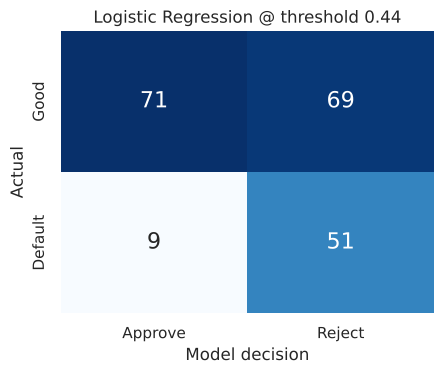

In [18]:
# Final model: refit is already done (best estimator trained on the training split). Evaluate at the chosen threshold.
final_proba = test_proba[best_name]
final_pred  = (final_proba >= THR).astype(int)
default_metrics = metrics(y_test, final_proba, THR)
default_metrics_05 = metrics(y_test, final_proba, 0.5)

print(f"{best_name} on the TEST set at threshold {THR:.2f}")
print(classification_report(y_test, final_pred, target_names=["Good", "Default"], digits=3))

# Bootstrap 95% confidence intervals: the test set is only 200 rows, so be honest about uncertainty
rng = np.random.default_rng(RANDOM_STATE); boots = {"Recall": [], "F1": [], "AUC-ROC": []}
yt = y_test.values
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() == yt[i].max(): continue
    boots["Recall"].append(recall_score(yt[i], final_pred[i])); boots["F1"].append(f1_score(yt[i], final_pred[i]))
    boots["AUC-ROC"].append(roc_auc_score(yt[i], final_proba[i]))
ci = {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in boots.items()}
for k, (lo, hi) in ci.items(): print(f"{k:8s} 95% CI: {lo:.3f} - {hi:.3f}")

cm = confusion_matrix(y_test, final_pred)
fig, ax = plt.subplots(figsize=(4.6, 3.9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 16},
            xticklabels=["Approve", "Reject"], yticklabels=["Good", "Default"])
ax.set_xlabel("Model decision"); ax.set_ylabel("Actual"); ax.set_title(f"{best_name} @ threshold {THR:.2f}")
plt.tight_layout(); save("10_final_confusion_matrix"); plt.show()

## 7. Explainability and Fairness
### 7.1 What drives the model's decisions?
Permutation importance on the test set (drop in AUC when a feature is shuffled), measured on the **original** features, so the result is readable by credit officers.

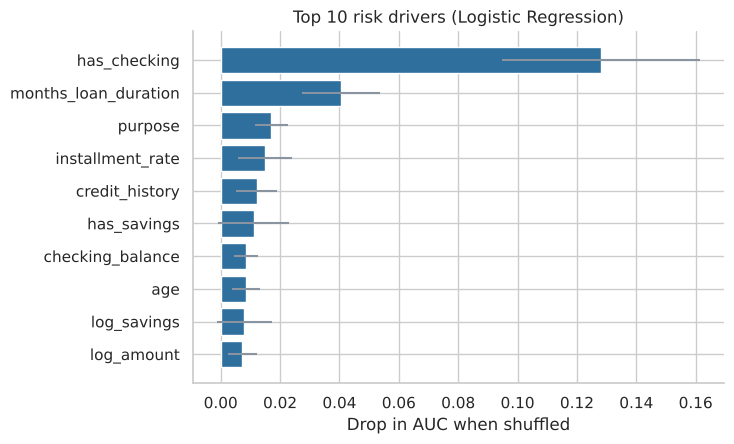

,importance
has_checking,0.1280
months_loan_duration,0.0405
purpose,0.0171
installment_rate,0.0148
credit_history,0.0121
has_savings,0.0111
checking_balance,0.0086
age,0.0085
log_savings,0.0080
log_amount,0.0073


In [19]:
pi = permutation_importance(tuned[best_name], X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
imp_err = pd.Series(pi.importances_std, index=X_test.columns)[imp.index]
top = imp.head(10)[::-1]

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(top.index, top.values, xerr=imp_err[top.index], color=C_GOOD, error_kw={"ecolor": C_NEUTRAL})
ax.set_xlabel("Drop in AUC when shuffled"); ax.set_title(f"Top 10 risk drivers ({best_name})")
plt.tight_layout(); save("11_feature_importance"); plt.show()
display(imp.head(10).round(4).to_frame("importance"))

### 7.2 Fairness audit and sensitive attributes
Using gender or marital status in credit decisions is restricted in many jurisdictions, and the brief asks us to avoid unfairly rejecting good customers. We therefore (a) test whether those columns help at all and (b) audit the final model's decisions by gender and age.

In [20]:
# (a) Sensitivity test: does adding gender + personal_status improve the selected model?
CAT_SENS = CAT + ["personal_status", "gender"]
X_s = data[NUM + CAT_SENS]
Xs_tr, Xs_te = X_s.loc[X_train.index], X_s.loc[X_test.index]
est = clone(search_space[best_name][0]).set_params(**{k.split("__")[1]: v for k, v in best_params[best_name].items()})
with_sens = Pipeline([("prep", make_preprocessor(NUM, CAT_SENS)), ("model", est)]).fit(Xs_tr, y_train)
auc_with = roc_auc_score(y_test, with_sens.predict_proba(Xs_te)[:, 1])
auc_without = roc_auc_score(y_test, final_proba)
display(pd.DataFrame({"Test AUC": {"Without gender / personal_status (our model)": auc_without,
                                      "With gender / personal_status": auc_with}}).round(3))

,Test AUC
Without gender / personal_status (our model),0.803
With gender / personal_status,0.798


**By gender**

,n,reject_rate,actual_default_rate,good_customers_wrongly_rejected,defaults_caught (recall)
gender,,,,,
female,61,0.607,0.328,0.463,0.900
male,139,0.597,0.288,0.505,0.825


**By age group**

,n,reject_rate,actual_default_rate,good_customers_wrongly_rejected,defaults_caught (recall)
age_group,,,,,
<=25,44,0.705,0.455,0.583,0.850
26-35,66,0.682,0.318,0.600,0.857
36-50,61,0.492,0.230,0.362,0.929
50+,29,0.483,0.172,0.458,0.600


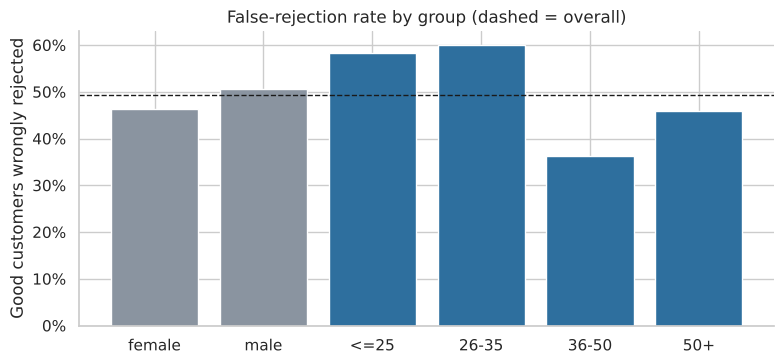

In [21]:
# (b) Audit the final model's decisions on the test set
audit = data.loc[X_test.index, ["gender", "age"]].copy()
audit["age_group"] = pd.cut(audit.age, [0, 25, 35, 50, 120], labels=["<=25", "26-35", "36-50", "50+"])
audit["actual"], audit["reject"] = y_test.values, final_pred

def group_report(col):
    g = audit.groupby(col, observed=True)
    out = pd.DataFrame({"n": g.size(),
        "reject_rate": g.reject.mean(),
        "actual_default_rate": g.actual.mean(),
        "good_customers_wrongly_rejected": g.apply(lambda d: d.loc[d.actual == 0, "reject"].mean()),
        "defaults_caught (recall)": g.apply(lambda d: d.loc[d.actual == 1, "reject"].mean())})
    return out.round(3)

gender_rep, age_rep = group_report("gender"), group_report("age_group")
display(Markdown("**By gender**")); display(gender_rep)
display(Markdown("**By age group**")); display(age_rep)

fig, ax = plt.subplots(figsize=(8, 3.8))
rep = pd.concat([gender_rep, age_rep])["good_customers_wrongly_rejected"]
ax.bar(rep.index.astype(str), rep.values, color=[C_NEUTRAL] * len(gender_rep) + [C_GOOD] * len(age_rep))
ax.axhline(final_pred[y_test.values == 0].mean(), color="k", ls="--", lw=1)
ax.set_ylabel("Good customers wrongly rejected"); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("False-rejection rate by group (dashed = overall)")
plt.tight_layout(); save("12_fairness_false_rejection"); plt.show()

Group sizes in the test set are small (a few dozen per group), so differences of a few percentage points are **not statistically conclusive**. Younger applicants are rejected more often, partly because their actual default rate is higher; because age rules vary by jurisdiction, compliance should review whether age may be used. The audit should be repeated on live decisions and re-run at every model refresh.

## 8. Business Impact
All figures are on the **held-out test set** (200 applicants, their actual loan amounts). Money figures depend on the stated assumptions (LGD 100%, 10% margin); the *bad-debt ratio* does not.

In [22]:
y_t = y_test.values
total_amt = amount_test.sum()

def evaluate_policy(reject, lgd=LGD, margin=MARGIN):
    """Business outcome if the applicants flagged in `reject` are declined (everyone else is approved)."""
    approve = ~reject
    approved_amt = amount_test[approve].sum()
    defaulted = amount_test[approve & (y_t == 1)].sum()                # principal at risk of loss in approved book
    lost_margin = (amount_test[reject & (y_t == 0)] * margin).sum()    # profit given up by declining good customers
    return {"approval_rate": approve.mean(), "good_customers_rejected": reject[y_t == 0].mean(),
            "defaults_caught (recall)": reject[y_t == 1].mean(),
            "bad_debt_ratio": defaulted / approved_amt, "defaulted_principal": defaulted, "lost_margin": lost_margin}

policies = {"Approve everyone (no model)": np.zeros(len(y_t), bool),
            f"Balanced (threshold {THR:.2f})": final_proba >= THR,
            f"Strict (threshold {STRICT_THR:.2f})": final_proba >= STRICT_THR}
pol = pd.DataFrame({k: evaluate_policy(v) for k, v in policies.items()}).T
base_loss = pol.iloc[0]["defaulted_principal"]
pol["principal_protected"] = base_loss - pol["defaulted_principal"]
pol["principal_protected_pct"] = pol["principal_protected"] / base_loss
pol["net_benefit_vs_no_model"] = pol["principal_protected"] * LGD - pol["lost_margin"]
display(pol.assign(**{c: pol[c].map("{:.1%}".format) for c in ["approval_rate", "good_customers_rejected", "defaults_caught (recall)",
                                                                  "bad_debt_ratio", "principal_protected_pct"]},
                   **{c: pol[c].map("{:,.0f}".format) for c in ["defaulted_principal", "lost_margin", "principal_protected", "net_benefit_vs_no_model"]}).T)

bal_key = f"Balanced (threshold {THR:.2f})"; strict_key = f"Strict (threshold {STRICT_THR:.2f})"
impact = {"bad_debt_ratio_before": float(pol.iloc[0]["bad_debt_ratio"]), "bad_debt_ratio_after": float(pol.loc[bal_key, "bad_debt_ratio"]),
          "defaulted_principal_before": float(base_loss), "defaulted_principal_after": float(pol.loc[bal_key, "defaulted_principal"]),
          "principal_protected": float(pol.loc[bal_key, "principal_protected"]), "principal_protected_pct": float(pol.loc[bal_key, "principal_protected_pct"]),
          "approval_rate": float(pol.loc[bal_key, "approval_rate"]), "good_customers_rejected_pct": float(pol.loc[bal_key, "good_customers_rejected"]),
          "lost_margin": float(pol.loc[bal_key, "lost_margin"]), "net_benefit": float(pol.loc[bal_key, "net_benefit_vs_no_model"])}
impact_strict = {"bad_debt_ratio_after": float(pol.loc[strict_key, "bad_debt_ratio"]), "approval_rate": float(pol.loc[strict_key, "approval_rate"]),
                 "good_customers_rejected_pct": float(pol.loc[strict_key, "good_customers_rejected"]), "recall": float(pol.loc[strict_key, "defaults_caught (recall)"]),
                 "principal_protected_pct": float(pol.loc[strict_key, "principal_protected_pct"]), "net_benefit": float(pol.loc[strict_key, "net_benefit_vs_no_model"])}

,Approve everyone (no model),Balanced (threshold 0.44),Strict (threshold 0.28)
approval_rate,100.0%,40.0%,14.0%
good_customers_rejected,0.0%,49.3%,80.7%
defaults_caught (recall),0.0%,85.0%,98.3%
bad_debt_ratio,38.9%,16.6%,6.7%
defaulted_principal,"280,001","36,817","4,591"
lost_margin,0,"25,433","37,606"
principal_protected,0,"243,184","275,410"
principal_protected_pct,0.0%,86.9%,98.4%
net_benefit_vs_no_model,0,"217,751","237,804"


In [23]:
# How sensitive is the net benefit to the two unknown business assumptions?
rows = []
for lgd in [0.5, 1.0]:
    for m in [0.05, 0.10, 0.20]:
        r = {"LGD": f"{lgd:.0%}", "margin": f"{m:.0%}"}
        for label, thr in [("Balanced", THR), ("Strict", STRICT_THR)]:
            e = evaluate_policy(final_proba >= thr, lgd=lgd, margin=m)
            r[f"{label}: net benefit"] = round((base_loss - e["defaulted_principal"]) * lgd - e["lost_margin"])
        rows.append(r)
sens_tbl = pd.DataFrame(rows); display(sens_tbl)

,LGD,margin,Balanced: net benefit,Strict: net benefit
0,50%,5%,108876,118902
1,50%,10%,96159,100099
2,50%,20%,70727,62493
3,100%,5%,230468,256607
4,100%,10%,217751,237804
5,100%,20%,192319,200198


### Operational efficiency: automated decision bands

,applicants,default_rate,share_of_volume
band,,,
Auto-approve,82,0.110,0.410
Manual review,73,0.315,0.365
Auto-reject,45,0.622,0.225


Cut-offs: auto-approve <= 0.44, auto-reject >= 0.62. Applications decided instantly: 64%


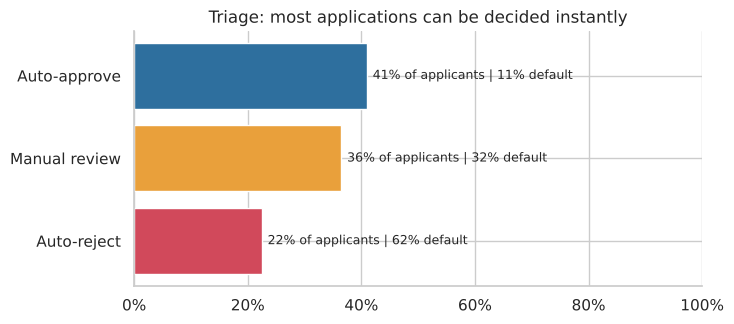

In [24]:
# Use training out-of-fold scores to define two cut-offs:
#   auto-approve below LOW  (observed default rate in the band <= 12%)
#   auto-reject  above HIGH (observed default rate in the band >= 60%)
#   everything between goes to a human credit officer
order = np.argsort(oof_best)
s_sorted, y_sorted = oof_best[order], y_train.values[order]
cum_low = np.cumsum(y_sorted) / np.arange(1, len(y_sorted) + 1)
LOW = s_sorted[np.where(cum_low <= 0.12)[0].max()] if (cum_low <= 0.12).any() else s_sorted[0]
cum_high = (np.cumsum(y_sorted[::-1]) / np.arange(1, len(y_sorted) + 1))[::-1]
HIGH = s_sorted[np.where(cum_high >= 0.60)[0].min()] if (cum_high >= 0.60).any() else 1.0

band = np.where(final_proba <= LOW, "Auto-approve", np.where(final_proba >= HIGH, "Auto-reject", "Manual review"))
bands = (pd.DataFrame({"band": band, "default": y_t}).groupby("band")
         .agg(applicants=("default", "size"), default_rate=("default", "mean")).reindex(["Auto-approve", "Manual review", "Auto-reject"]))
bands["share_of_volume"] = bands.applicants / len(y_t)
display(bands.round(3))
auto_share = 1 - bands.loc["Manual review", "share_of_volume"]
print(f"Cut-offs: auto-approve <= {LOW:.2f}, auto-reject >= {HIGH:.2f}. Applications decided instantly: {auto_share:.0%}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
cols = [C_GOOD, "#E9A03B", C_BAD]
ax.barh(bands.index[::-1], bands.share_of_volume[::-1], color=cols[::-1])
for i, (sh, dr) in enumerate(zip(bands.share_of_volume[::-1], bands.default_rate[::-1])):
    ax.text(sh + .01, i, f"{sh:.0%} of applicants | {dr:.0%} default", va="center", fontsize=9)
ax.set_xlim(0, 1.0); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Triage: most applications can be decided instantly")
plt.tight_layout(); save("13_decision_bands"); plt.show()

## 9. Summary, Recommendations and Limitations

In [25]:
top5 = [k for k, _ in imp.head(5).items()]
display(Markdown(f'''
### Key results
* **Selected model: {best_name}.** At the balanced threshold ({THR:.2f}) on the held-out test set it catches **{default_metrics['Recall']:.0%} of defaults** (95% CI {ci['Recall'][0]:.0%}-{ci['Recall'][1]:.0%}), with F1 = **{default_metrics['F1']:.2f}** and AUC-ROC = **{default_metrics['AUC-ROC']:.2f}** (95% CI {ci['AUC-ROC'][0]:.2f}-{ci['AUC-ROC'][1]:.2f}). Accuracy is {default_metrics['Accuracy']:.0%} and is deliberately not the target.
* **Risk mitigation:** the bad-debt ratio of the approved book (defaulted principal / approved principal) falls from **{impact['bad_debt_ratio_before']:.1%}** to **{impact['bad_debt_ratio_after']:.1%}**; **{impact['principal_protected_pct']:.0%}** of defaulted principal is avoided.
* **Cost:** {impact['good_customers_rejected_pct']:.0%} of good customers are rejected and {impact['approval_rate']:.0%} of applicants are approved. This is the price of a high-recall policy; the threshold lets the bank move along this trade-off.
* **Strict policy:** minimising monetary loss under the assumed costs (threshold {STRICT_THR:.2f}) would approve only {impact_strict['approval_rate']:.0%} of applicants and reject {impact_strict['good_customers_rejected_pct']:.0%} of good customers, which conflicts with the brief's fairness goal, so it is shown as an upper bound on protection, not the recommendation.
* **Operational efficiency:** {auto_share:.0%} of applications fall into an automatic approve / reject band; only the middle band needs a credit officer.
* **Top risk drivers:** {', '.join(f'`{c}`' for c in top5)}.
'''))


### Key results
* **Selected model: Logistic Regression.** At the balanced threshold (0.44) on the held-out test set it catches **85% of defaults** (95% CI 75%-94%), with F1 = **0.57** and AUC-ROC = **0.80** (95% CI 0.73-0.87). Accuracy is 61% and is deliberately not the target.
* **Risk mitigation:** the bad-debt ratio of the approved book (defaulted principal / approved principal) falls from **38.9%** to **16.6%**; **87%** of defaulted principal is avoided.
* **Cost:** 49% of good customers are rejected and 40% of applicants are approved. This is the price of a high-recall policy; the threshold lets the bank move along this trade-off.
* **Strict policy:** minimising monetary loss under the assumed costs (threshold 0.28) would approve only 14% of applicants and reject 81% of good customers, which conflicts with the brief's fairness goal, so it is shown as an upper bound on protection, not the recommendation.
* **Operational efficiency:** 64% of applications fall into an automatic approve / reject band; only the middle band needs a credit officer.
* **Top risk drivers:** `has_checking`, `months_loan_duration`, `purpose`, `installment_rate`, `credit_history`.


### Recommendations
1. **Deploy the selected model as a decision-support score**, starting with the auto-approve / manual-review / auto-reject triage, and keep a credit officer in the loop for the middle band.
2. **Set the threshold from the bank's own numbers.** The balanced threshold is a policy choice (recall target 80%); the strict policy depends on assumed LGD (100%) and margin (10%). Replace them with actual recovery rates and margins and re-run Sections 6 and 8.
3. **Tighten policy around the main risk drivers** found in Section 7.1 (checking-account status, loan duration, loan purpose, installment rate, credit history).
4. **Do not use gender or marital status** as model inputs; they add no accuracy and create regulatory risk. Re-run the fairness audit on live decisions.
5. **Monitor and retrain**: track recall, approval rate and bad-debt ratio monthly; retrain at least annually or when the applicant mix shifts.

### Limitations
* Only **1,000 historic loans**; the test set has 200 rows, so metrics carry wide confidence intervals.
* Data contains only *accepted* loans' outcomes (**selection bias**); rejected applicants' behaviour is unknown.
* Business parameters (LGD, margin) are **assumptions**, not data; the recall target (80%) is a policy choice.
* Several columns are ambiguous (e.g. units of balances, meaning of missing values); the interpretations in Section 2.1 should be confirmed with the data owner.
* Next steps: gradient boosting, probability calibration, cost-sensitive training, and a champion/challenger pilot.

In [26]:
# Persist the numbers used by the PowerPoint deck
results = {
    "n_rows": int(len(df)), "default_rate": float(df.default.mean()), "best_model": best_name, "threshold": THR,
    "cv_table": cv_tbl.round(4).to_dict("index"), "test_table_at_0.5": test_tbl.round(4).to_dict("index"),
    "final_metrics": {k: float(v) for k, v in default_metrics.items()},
    "final_metrics_at_0.5": {k: float(v) for k, v in default_metrics_05.items()},
    "ci": {k: [float(a), float(b)] for k, (a, b) in ci.items()},
    "confusion_matrix": cm.tolist(), "impact": impact, "impact_strict": impact_strict, "policies": pol.reset_index().to_dict("records"), "strict_threshold": STRICT_THR,
    "top_features": imp.head(10).round(4).to_dict(), "bands": bands.round(4).reset_index().to_dict("records"),
    "band_cutoffs": [float(LOW), float(HIGH)], "sensitivity": sens_tbl.to_dict("records"),
    "fairness_gender": gender_rep.reset_index().to_dict("records"), "fairness_age": age_rep.reset_index().astype({"age_group": str}).to_dict("records"),
    "auc_with_sensitive": float(auc_with), "auc_without_sensitive": float(auc_without),
    "assumptions": {"LGD": LGD, "margin": MARGIN},
    "curves": {"threshold": thresholds[::5].tolist(), "recall": rec_curve[::5].round(4).tolist(), "f1": f1_curve[::5].round(4).tolist(), "good_rejected": rej_good[::5].round(4).tolist()},
}
with open("results.json", "w") as f: json.dump(results, f, indent=2, default=str)
print("Saved results.json and", len(os.listdir(FIG_DIR)), "figures")

Saved results.json and 14 figures
